# Office with occupied coffee machines: adapting the plan to occupancy

The coffee machines `C1` and `C2` can be **occupied by someone else**. At every step a free machine becomes
occupied with probability $X$, and then stays occupied for exactly $T$ steps. The agent always sees both
*clocks* (steps until the machine is free, $0$ = free). If it steps into an occupied machine it **queues**: it
waits in the cell and gets the coffee when the machine frees. It cannot leave the queue (with $T < 21$, the
$C_1 \leftrightarrow C_2$ distance, leaving is never better). The arrival is judged against the clock the agent saw
when acting (first come, first served).

**Why this fits SF-FSA-VI.** Occupancy changes the *dynamics* of the coffee stage, not its features: obtaining
coffee after a wait of $k$ steps gives $\gamma^k e_{C}$. So the coffee stage is a stochastic MDP over
(position, clock $C_1$, clock $C_2$) with the same 6 features, and only the coffee stage needs it: after the coffee
the clocks are irrelevant, so the high-level weights $w(u)$ of SF-FSA-VI are unchanged.

We compare, on the coffee stage with the exact SF-FSA-VI weights $w(u_0)$:

| policy | what it does |
|---|---|
| **naive** | SF-FSA-VI as in the paper: the base-Office optimal policy for $w(u_0)$, blind to the clocks (walks to its machine and queues) |
| **GPI (lifted)** | GPI over the 6 corner policies $\pi(e_j)$, with their SFs *lifted* to the occupancy MDP (no new samples) and re-evaluated at the current clocks every step |
| **metapolicy** | best of the corner policies' own actions at every (position, clocks), by restricted policy iteration |
| $\pi^{\mathrm{hyb}}$ | any action, scored by the metapolicy's value |
| **exact** | value iteration on the full occupancy MDP |

Main setting: $T = 10$. Two tasks: the paper's **sequential** task (coffee $\to$ mail $\to$ office) and
**coffee $\to$ office**, where the better machine is $C_2$.

In [1]:
import os
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla

SF_FSA_VI_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", "RM", "sf-fsa-vi"))
if SF_FSA_VI_ROOT not in sys.path:
    sys.path.insert(0, SF_FSA_VI_ROOT)
from envs.grid_envs import Office  # noqa: E402

np.set_printoptions(suppress=True, precision=3)

office = Office(add_obj_to_start=True, random_act_prob=0.0)
GAMMA = 0.99
NA, D = office.a_dim, office.feat_dim
OBJ = office.PHI_OBJ_TYPES                     # ['C1', 'C2', 'O1', 'O2', 'M1', 'M2']
iC1, iC2 = OBJ.index("C1"), OBJ.index("C2")

states = [office.state_to_coords[i] for i in range(office.s_dim)]
sidx = {s: i for i, s in enumerate(states)}
S = len(states)
ROWS = np.arange(S)
NEXT = np.zeros((S, NA), dtype=int)
PHI = np.zeros((S, NA, D))
DONE = np.zeros((S, NA), dtype=bool)
for s in states:
    for a in range(NA):
        ns = office.base_movement(s, a)
        NEXT[sidx[s], a] = sidx[ns]
        PHI[sidx[s], a] = office.features(s, a, ns)
        DONE[sidx[s], a] = office.is_done(s, a, ns)
EXIT = {office.MAP[pos]: sidx[pos] for pos in office.object_ids}
START = sidx[(9, 3)]
FREE = np.array([s for s in range(S) if office.MAP[states[s]] not in OBJ])   # non-object cells
print(f"|S| = {S} cells ({len(FREE)} non-object), start {states[START]}, exits {EXIT}")

|S| = 109 cells (103 non-object), start (9, 3), exits {'M2': 20, 'O1': 98, 'C1': 2, 'O2': 35, 'C2': 6, 'M1': 108}


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/opt/anaconda3/envs/okb/lib/python3.10/site-packages/gym/spaces/box.py:84: UserWarning: WARN: Box bound precision lowered by casting to float32
  logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


## Base Office and the SF-FSA-VI weights

Exact policy iteration on the base Office (as in notebooks 14-15). The high-level weights follow SF-FSA-VI:
$w_j(u)$ is the optimal value of the rest of the task when standing on exit $\varepsilon_j$, and $0$ for exits that
do not advance the automaton.

In [2]:
def base_system(actions):
    cont = ~DONE[ROWS, actions]
    A = np.eye(S)
    A[ROWS[cont], NEXT[ROWS, actions][cont]] -= GAMMA
    return A, PHI[ROWS, actions]


def base_pi(w):
    pi = np.zeros(S, dtype=int)
    while True:
        A, B = base_system(pi)
        V = np.linalg.solve(A, B @ w)
        Q = PHI @ w + GAMMA * np.where(DONE, 0.0, V[NEXT])
        best = Q.argmax(axis=1)
        new = np.where(Q[ROWS, pi] >= Q[ROWS, best] - 1e-12, pi, best)
        if np.array_equal(new, pi):
            return pi, V
        pi = new


def exit_weights(next_w, exits):
    # w_j = optimal value of next_w from exit j, for the exits that advance the automaton
    _, V = base_pi(next_w)
    w = np.zeros(D)
    for e in exits:
        w[OBJ.index(e)] = V[EXIT[e]]
    return w


w_office = np.zeros(D)
w_office[[OBJ.index("O1"), OBJ.index("O2")]] = 1.0
w_mail = exit_weights(w_office, ("M1", "M2"))
TASKS = {"sequential": exit_weights(w_mail, ("C1", "C2")),        # coffee -> mail -> office
         "coffee->office": exit_weights(w_office, ("C1", "C2"))}
for name, w in TASKS.items():
    print(f"{name:>15s}: w(u0) on C1, C2 = {w[iC1]:.3f}, {w[iC2]:.3f}")

CORNERS = [base_pi(np.eye(D)[j])[0] for j in range(D)]          # pi(e_j), one action per cell

     sequential: w(u0) on C1, C2 = 0.904, 0.810
 coffee->office: w(u0) on C1, C2 = 0.895, 0.970


## The occupancy MDP of the coffee stage

Augmented state $x = (s, c_1, c_2)$ with clocks $c_i \in \{0, \dots, T\}$; $|x| = 109 \cdot (T+1)^2$. Each clock is
an independent Markov chain ($0 \to T$ w.p. $X$, otherwise counts down), so the joint clock kernel is a Kronecker
product. Entering coffee machine $C_i$ with clock $c_i$ is terminal with feature $\gamma^{c_i} e_{C_i}$ (queue
for $c_i$ steps); entering any other object is terminal with its one-hot feature, as in the base Office.

In [3]:
class OccupancyMDP:
    def __init__(self, T, X):
        self.T, self.X, self.C = T, X, T + 1
        K = np.zeros((self.C, self.C))
        K[0, 0], K[0, T] = 1 - X, X
        K[np.arange(1, self.C), np.arange(self.C - 1)] = 1.0
        self.K = K
        stat = np.r_[1.0, np.full(T, X)]
        self.stat = np.kron(stat, stat) / stat.sum() ** 2          # stationary joint clocks
        CC = self.C * self.C
        self.N = S * CC
        self.pos = np.repeat(ROWS, CC)
        self.c1 = np.tile(np.repeat(np.arange(self.C), self.C), S)
        self.c2 = np.tile(np.tile(np.arange(self.C), self.C), S)
        KJ = sp.csr_matrix(np.kron(K, K))
        self.P, F = [], []
        for a in range(NA):
            move = sp.csr_matrix(((~DONE[:, a]).astype(float), (ROWS, NEXT[:, a])), shape=(S, S))
            self.P.append(sp.kron(move, KJ, format="csr"))
            Fa = np.repeat(PHI[:, a], CC, axis=0)
            for i, clock in ((iC1, self.c1), (iC2, self.c2)):
                hit = Fa[:, i] > 0
                Fa[hit, i] = GAMMA ** clock[hit]                    # queue for `clock` steps
            F.append(Fa)
        self.F = np.stack(F, axis=1)                                # (N, A, D)
        self.I = sp.identity(self.N, format="csc")
        self._cols = np.arange(self.N)

    def x(self, s, c1, c2):
        return (s * self.C + c1) * self.C + c2

    def _P_pi(self, actions):
        P = sp.csr_matrix((self.N, self.N))
        for a in range(NA):
            P = P + sp.diags((actions == a).astype(float)) @ self.P[a]
        return P

    def sf(self, actions):                 # Psi(x, pi(x)), (N, D)
        lu = spla.splu((self.I - GAMMA * self._P_pi(actions)).tocsc())
        return lu.solve(self.F[self._cols, actions])

    def value(self, actions, w):
        A = (self.I - GAMMA * self._P_pi(actions)).tocsc()
        return spla.spsolve(A, self.F[self._cols, actions] @ w)

    def q(self, V, w):                     # (N, A)
        return np.stack([self.F[:, a] @ w + GAMMA * (self.P[a] @ V) for a in range(NA)], axis=1)

    def sf_q(self, Psi):                   # (N, A, D)
        return np.stack([self.F[:, a] + GAMMA * (self.P[a] @ Psi) for a in range(NA)], axis=1)

    def optimal(self, w):
        pi = np.zeros(self.N, dtype=int)
        while True:
            V = self.value(pi, w)
            Q = self.q(V, w)
            best = Q.argmax(axis=1)
            new = np.where(Q[self._cols, pi] >= Q[self._cols, best] - 1e-12, pi, best)
            if np.array_equal(new, pi):
                return pi, V
            pi = new

    def meta(self, w, basis):              # restricted PI over the basis policies' own actions
        own = np.stack(basis)
        j = np.zeros(self.N, dtype=int)
        while True:
            actions = own[j, self._cols]
            V = self.value(actions, w)
            Q = self.q(V, w)
            Qj = Q[self._cols[None, :], own]
            best = Qj.argmax(axis=0)
            new = np.where(Qj[j, self._cols] >= Qj[best, self._cols] - 1e-12, j, best)
            if np.array_equal(new, j):
                return actions, V, Q
            j = new

    def lift(self, base_actions):          # a base policy that ignores the clocks
        return base_actions[self.pos]

## Lifting the corner policies costs no samples

A base policy that ignores the clocks follows a deterministic path from $s$ and enters exit $j$ after $d$ steps.
Only the wait at a coffee machine depends on occupancy: it equals the clock seen at step $d-1$, whose distribution
is the clock chain propagated $d-1$ steps. So the lifted SF is
$\Psi_j(s, c) = \gamma^{d-1}\, \mathbb E[\gamma^{\,c_j(d-1)} \mid c_j]$ for a coffee exit and $\gamma^{d-1}$ otherwise,
a small matrix power instead of learning. We check it against exact evaluation in the occupancy MDP.

In [4]:
def lift_closed_form(m, base_actions):
    Psi = np.zeros((m.N, D))
    powers = [np.linalg.matrix_power(m.K, n) for n in range(S + 1)]
    disc = GAMMA ** np.arange(m.C)
    CC = m.C * m.C
    for s in range(S):
        x, d = s, 0
        while d <= S:
            a = base_actions[x]
            d += 1
            if DONE[x, a]:
                break
            x = NEXT[x, a]
        else:
            continue                         # never reaches an exit
        j = int(PHI[x, a].argmax())
        rows = slice(s * CC, (s + 1) * CC)
        if j in (iC1, iC2):
            clock = (m.c1 if j == iC1 else m.c2)[rows]
            Psi[rows, j] = GAMMA ** (d - 1) * (powers[d - 1][clock] @ disc)
        else:
            Psi[rows, j] = GAMMA ** (d - 1)
    return Psi


m = OccupancyMDP(T=10, X=0.1)
err = max(np.abs(lift_closed_form(m, a) - m.sf(m.lift(a))).max() for a in CORNERS)
print(f"T=10, X=0.1: |closed-form lifting - exact evaluation| <= {err:.1e}  over all {m.N} states x 6 corner policies")

T=10, X=0.1: |closed-form lifting - exact evaluation| <= 8.9e-16  over all 13189 states x 6 corner policies

## Comparing the policies

Values are converted to **extra steps** with respect to the exact optimum, $\log(V^*/V) / \log(1/\gamma)$: since
every reward is a discounted exit, a value ratio is a delay. We report it from the paper's start cell $(9,3)$
(clocks drawn from their stationary distribution), averaged over all non-object cells, and in the worst
(position, clocks) state, together with the % of such states where the policy is suboptimal.

In [5]:
POLICIES = ("naive", "GPI", "meta", "hyb")


def evaluate(T, X, w):
    m = OccupancyMDP(T, X)
    _, V_star = m.optimal(w)
    V = {"naive": m.value(m.lift(base_pi(w)[0]), w)}
    lifted = [m.lift(a) for a in CORNERS]
    Q_gpi = np.max(np.stack([m.sf_q(lift_closed_form(m, a)) @ w for a in CORNERS]), axis=0)
    V["GPI"] = m.value(Q_gpi.argmax(axis=1), w)
    _, V["meta"], Q_meta = m.meta(w, lifted)
    V["hyb"] = m.value(Q_meta.argmax(axis=1), w)

    CC = m.C * m.C
    on_free = np.isin(m.pos, FREE)
    steps = lambda v_star, v: np.maximum(np.log(v_star / v) / np.log(1 / GAMMA), 0.0)
    start = lambda v: v.reshape(S, CC)[START] @ m.stat
    cells = lambda v: (v.reshape(S, CC)[FREE] @ m.stat).mean()
    row = {}
    for name in POLICIES:
        per_state = steps(V_star[on_free], V[name][on_free])
        row[name] = dict(start=steps(start(V_star), start(V[name])),
                         cells=steps(cells(V_star), cells(V[name])),
                         worst=per_state.max(),
                         subopt=100 * np.mean(per_state > 1e-6))
    return row, m, V_star


def print_table(results):
    print(f"{'X':>5s} | " + " | ".join(f"{n:^29s}" for n in POLICIES))
    print(f"{'':>5s} | " + " | ".join(f"{'start':>6s}{'cells':>7s}{'worst':>7s}{'%sub':>7s} " for _ in POLICIES))
    for X, row in results.items():
        print(f"{X:>5.2f} | " + " | ".join(
            f"{row[n]['start']:6.2f}{row[n]['cells']:7.3f}{row[n]['worst']:7.2f}{row[n]['subopt']:7.1f} " for n in POLICIES))


T_MAIN = 10
X_GRID = (0.0, 0.02, 0.05, 0.1, 0.2, 0.3)
RESULTS = {}
for task, w in TASKS.items():
    t0 = time.perf_counter()
    RESULTS[task] = {X: evaluate(T_MAIN, X, w)[0] for X in X_GRID}
    print(f"\n{task}, T={T_MAIN}  (extra steps vs exact; {time.perf_counter() - t0:.0f}s)")
    print_table(RESULTS[task])


sequential, T=10  (extra steps vs exact; 3s)
    X |             naive             |              GPI              |             meta              |              hyb             
      |  start  cells  worst   %sub  |  start  cells  worst   %sub  |  start  cells  worst   %sub  |  start  cells  worst   %sub 
 0.00 |   0.00  0.000   6.00    4.5  |   0.00  0.000   0.00    0.0  |   0.00  0.000   0.00    0.0  |   0.00  0.000   0.00    0.0 
 0.02 |   0.00  0.030   5.26   10.3  |   0.00  0.001   0.06    0.3  |   0.00  0.004   0.11    1.9  |   0.00  0.000   0.00    0.0 
 0.05 |   0.00  0.035   4.27    8.6  |   0.00  0.002   0.45    0.4  |   0.00  0.004   0.24    1.9  |   0.00  0.001   0.22    0.0 
 0.10 |   0.00  0.031   3.58    6.1  |   0.00  0.001   0.38    0.3  |   0.00  0.002   0.36    1.0  |   0.00  0.000   0.26    0.2 
 0.20 |   0.00  0.040   3.48    6.5  |   0.00  0.000   0.23    2.2  |   0.00  0.002   0.53    1.0  |   0.00  0.000   0.23    0.1 
 0.30 |   0.00  0.059   4.07    6.0  |  


coffee->office, T=10  (extra steps vs exact; 4s)
    X |             naive             |              GPI              |             meta              |              hyb             
      |  start  cells  worst   %sub  |  start  cells  worst   %sub  |  start  cells  worst   %sub  |  start  cells  worst   %sub 
 0.00 |   0.00  0.000   4.00    2.4  |   0.00  0.000   0.00    0.0  |   0.00  0.000   0.00    0.0  |   0.00  0.000   0.00    0.0 
 0.02 |   0.00  0.006   3.37    5.0  |   0.00  0.001   0.02    1.5  |   0.00  0.000   0.00    0.0  |   0.00  0.000   0.00    0.0 
 0.05 |   0.00  0.006   2.49    3.6  |   0.00  0.000   0.01    0.8  |   0.00  0.000   0.00    0.0  |   0.00  0.000   0.00    0.0 
 0.10 |   0.00  0.010   2.37    2.6  |   0.00  0.000   0.00    0.0  |   0.00  0.000   0.00    0.0  |   0.00  0.000   0.00    0.0 
 0.20 |   0.00  0.032   4.01    3.9  |   0.00  0.000   0.24    0.1  |   0.00  0.000   0.00    0.0  |   0.00  0.000   0.00    0.0 
 0.30 |   0.02  0.057   5.07    5.1 

## What the agent plans to do, as a function of the clock

Coffee $\to$ office task, $X = 0.1$, and $T = 20$ so that the effect is visible (at $T = 10$ only a handful of
cells change: $C_2$ is worth about 8 steps more than $C_1$ for this task, so a wait of at most 10 rarely justifies
the switch). For every start cell we follow the exact optimal policy with the clocks counting down and no new
occupation (the plan it is executing *now*) and record which machine it ends at. $C_1$ is free; $C_2$ is
occupied with $\tau$ steps left. Cells outlined in black changed machine with respect to $\tau = 0$. The naive
SF-FSA-VI policy ignores the clocks altogether.

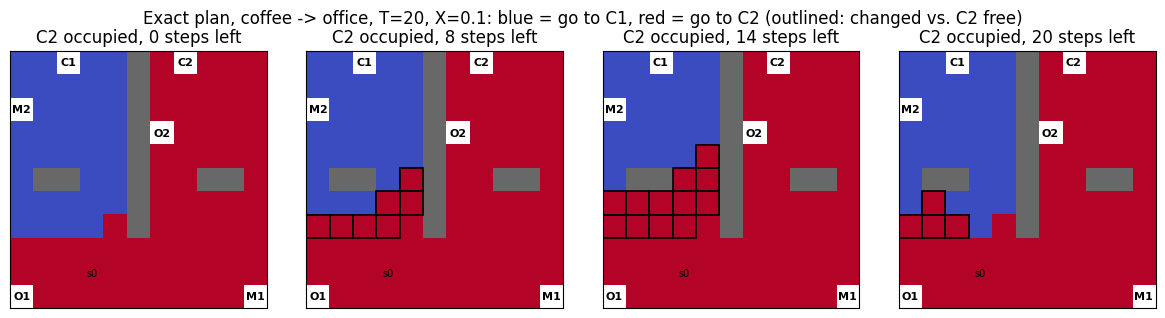

In [6]:
def planned_machine(m, actions, s, c1, c2):
    for _ in range(4 * S):
        a = actions[m.x(s, c1, c2)]
        if DONE[s, a]:
            return office.MAP[states[NEXT[s, a]]]
        s, c1, c2 = NEXT[s, a], max(c1 - 1, 0), max(c2 - 1, 0)
    return None


m = OccupancyMDP(20, 0.1)
pi_star, _ = m.optimal(TASKS["coffee->office"])
TAUS = (0, 8, 14, 20)
base_plan = {s: planned_machine(m, pi_star, s, 0, 0) for s in FREE}
fig, axes = plt.subplots(1, len(TAUS), figsize=(3.0 * len(TAUS), 3.2))
for ax, tau in zip(axes, TAUS):
    grid = np.full(office.MAP.shape, np.nan)
    for s in FREE:
        target = planned_machine(m, pi_star, s, 0, tau)
        grid[states[s]] = {"C1": 0.0, "C2": 1.0}.get(target, 0.5)
        if target != base_plan[s]:
            r, c = states[s]
            ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, ec="k", lw=1.2))
    walls = office.MAP == "X"
    ax.imshow(np.where(walls, np.nan, grid), cmap="coolwarm", vmin=0, vmax=1)
    ax.imshow(np.where(walls, 1.0, np.nan), cmap="Greys", vmin=0, vmax=1.5)
    for pos in office.object_ids:
        ax.text(pos[1], pos[0], office.MAP[pos], ha="center", va="center", fontsize=8, weight="bold")
    ax.text(3, 9, "s0", ha="center", va="center", fontsize=7)
    ax.set_title(f"C2 occupied, {tau} steps left")
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Exact plan, coffee -> office, T=20, X=0.1: blue = go to C1, red = go to C2 (outlined: changed vs. C2 free)")
fig.tight_layout()
os.makedirs(os.path.join("..", "notes", "figures"), exist_ok=True)
fig.savefig(os.path.join("..", "notes", "figures", "office_occupancy_plan.pdf"), bbox_inches="tight")
plt.show()

**An occupied machine can be better than a free one.** The outlined cells switch from $C_1$ to $C_2$ when $C_2$
becomes *occupied*. With $X = 0.1$, a free machine 13 steps away has a $1 - 0.9^{13} \approx 75\%$ chance of being
taken before the agent arrives, and then it waits up to $T = 20$ steps. An occupied machine whose clock runs out
just as the agent arrives is effectively reserved, because new occupations only start on a free machine. So the
pull towards $C_2$ peaks when $\tau$ is about the walking time ($\tau = 14$), and fades when the remaining wait
gets long ($\tau = 20$). A clock-blind policy cannot exploit this.

## Longer occupations: $T = 20$

Same comparison with $T = 20$ (still below the 21-step $C_1 \leftrightarrow C_2$ distance, so the queue rule is
still harmless).

In [7]:
for task, w in TASKS.items():
    print(f"\n{task}, T=20")
    print_table({X: evaluate(20, X, w)[0] for X in (0.05, 0.2)})


sequential, T=20


    X |             naive             |              GPI              |             meta              |              hyb             
      |  start  cells  worst   %sub  |  start  cells  worst   %sub  |  start  cells  worst   %sub  |  start  cells  worst   %sub 
 0.05 |   0.00  0.343  16.00   15.9  |   0.00  0.013   1.77    1.6  |   0.00  0.014   0.89    1.2  |   0.00  0.000   0.36    0.0 
 0.20 |   0.00  0.494  16.00   16.9  |   0.00  0.037   3.69    2.9  |   0.00  0.010   3.24    1.0  |   0.00  0.000   0.27    0.0 

coffee->office, T=20


    X |             naive             |              GPI              |             meta              |              hyb             
      |  start  cells  worst   %sub  |  start  cells  worst   %sub  |  start  cells  worst   %sub  |  start  cells  worst   %sub 
 0.05 |   0.10  0.296  14.00   17.4  |   0.05  0.031   1.90    4.4  |   0.00  0.000   0.00    0.0  |   0.00  0.000   0.00    0.0 
 0.20 |   0.70  0.459  14.00   15.4  |   0.02  0.031   3.24    3.3  |   0.00  0.000   0.00    0.0  |   0.00  0.000   0.00    0.0 


## Reading the result

*(Numbers from the tables above.)*

- **Only the coffee stage changes.** Occupancy is a change of dynamics with the same features, so the SF-FSA-VI
  weights after the coffee are untouched, and the coffee stage is an ordinary stochastic SF problem on
  (position, clocks).
- **From the paper's start cell the decision is trivial for the sequential task**: $C_1$ is 3 steps closer *and*
  its continuation (mail $M_2$ is 4 steps away) is worth about 11 more steps, so waiting up to $T$ steps for $C_1$
  always beats switching. Occupancy only matters in the states where the two machines are close in value, which
  is why averages over start cells are small and the worst-case column is the informative one.
- **The naive SF-FSA-VI policy, blind to the clocks, loses 2.4-6 steps in the worst state at $T = 10$
  (suboptimal in 2-10% of the (position, clocks) states) and 14-16 steps at $T = 20$ (about 16% of the states).**
- **GPI over the lifted corner policies already adapts**: when a clock jumps, the lifted SF of "go to that
  machine" drops and the argmax switches machine. Its worst case is at most 0.54 steps at $T = 10$ and 3.7 at
  $T = 20$, without a single new sample. What it misses is anticipation: it scores each action as if it then
  committed to one machine.
- **The $X = 0$ row is not trivial**: the states include clocks that are already running (an occupation known
  now, never repeated). There GPI over the lifted corners is exact, while the naive policy loses up to 6 steps.
  With deterministic movement and no future surprises, the corner policies are enough.
- **The metapolicy and $\pi^{\mathrm{hyb}}$ close most of the remaining gap**: on coffee $\to$ office both are
  exact for every $T$ and $X$ tested. On the sequential task the metapolicy is within 0.63 steps at $T = 10$ but
  3.2 at $T = 20$, while $\pi^{\mathrm{hyb}}$ stays within 0.46 steps everywhere, from the same 6 corner
  policies.